# LAPORAN TUGAS 2: Implementasi Pipeline Pemrosesan Batch
## Hadoop MapReduce vs Apache Spark
**Kelas:** ITPL3
**Mata Kuliah:** IT Platform and Infrastructure  
**Dosen Pengampu:** Hanafi, S.Kom., M.Eng., Ph.D.
---
### Tujuan Eksperimen
Membandingkan performa dua arsitektur Big Data utama pada dataset **HTTP Server Access Log** yang sama:
1. **Hadoop MapReduce** (Berbasis Disk I/O menggunakan Hadoop Streaming Python)
2. **Apache Spark** (Berbasis In-Memory menggunakan **RDD API** dan **DataFrame API**)


## Tahap 1: Persiapan Lingkungan Kerja (Environment Setup)
Menginstal pustaka `pyspark` dan `psutil`, serta mengunduh Apache Hadoop 3.3.6 untuk eksekusi Hadoop Streaming.


In [ ]:
!pip install -q pyspark psutil pandas matplotlib seaborn

import os
if not os.path.exists("/content/hadoop-3.3.6"):
    print("Mengunduh Apache Hadoop 3.3.6...")
    !wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz
    !tar -xzf hadoop-3.3.6.tar.gz
    !rm hadoop-3.3.6.tar.gz
    print("Hadoop berhasil diekstrak!")

java_home = os.popen("dirname $(dirname $(readlink -f $(which java)))").read().strip()
os.environ["JAVA_HOME"] = java_home
os.environ["HADOOP_HOME"] = "/content/hadoop-3.3.6"
os.environ["PATH"] += os.pathsep + "/content/hadoop-3.3.6/bin"
!hadoop version | head -n 1


Mengunduh Apache Hadoop 3.3.6...
Hadoop berhasil diekstrak!
[0.019s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## Tahap 2: Pembuatan Dataset Log Server Sintetis
Membangkitkan dataset log server dalam 3 skala ukuran: **500K baris (~39 MB)**, **1.5M baris (~118 MB)**, dan **3M baris (~236 MB)**.


In [ ]:
import os, random
from datetime import datetime, timedelta

for d in ["data", "mapreduce", "spark", "results"]:
    os.makedirs(f"repo_tugas2/{d}", exist_ok=True)

IPS = [f"192.168.1.{i}" for i in range(1, 255)] + [f"10.0.0.{i}" for i in range(1, 255)]
ENDPOINTS = ["/index.html", "/api/v1/login", "/api/v1/data", "/dashboard", "/static/app.js", "/admin"]
STATUS_CODES = [200, 200, 200, 200, 301, 400, 403, 404, 500, 502]
METHODS = ["GET", "POST", "PUT", "DELETE"]

def generate_log_file(filename, num_lines):
    start_time = datetime(2026, 10, 1, 0, 0, 0)
    with open(filename, "w") as f:
        for i in range(num_lines):
            ip = random.choice(IPS)
            ts = (start_time + timedelta(seconds=i)).strftime("%d/%b/%Y:%H:%M:%S +0700")
            method, ep, st = random.choice(METHODS), random.choice(ENDPOINTS), random.choice(STATUS_CODES)
            b_sent = random.randint(200, 50000) if st != 404 else 0
            f.write(f'{ip} - - [{ts}] "{method} {ep} HTTP/1.1" {st} {b_sent}\n')
    print(f"[Selesai] {filename} ({num_lines:,} baris | {os.path.getsize(filename)/(1024*1024):.2f} MB)")

datasets = {
    "500K_rows": ("repo_tugas2/data/access_500k.log", 500_000),
    "1.5M_rows": ("repo_tugas2/data/access_1.5m.log", 1_500_000),
    "3M_rows":   ("repo_tugas2/data/access_3m.log", 3_000_000)
}
for label, (path, lines) in datasets.items():
    if not os.path.exists(path):
        generate_log_file(path, lines)


[Selesai] repo_tugas2/data/access_500k.log (500,000 baris | 39.33 MB)
[Selesai] repo_tugas2/data/access_1.5m.log (1,500,000 baris | 117.99 MB)
[Selesai] repo_tugas2/data/access_3m.log (3,000,000 baris | 235.99 MB)


## Tahap 3: Implementasi Hadoop MapReduce (`mapper.py` & `reducer.py`)
Mapper mem-parsing setiap baris log menggunakan Regex dan mengeluarkan pasangan `status_code` beserta `1,bytes_sent`. Reducer menjumlahkan total request dan total bytes untuk setiap kode status HTTP.


In [ ]:
%%writefile repo_tugas2/mapreduce/mapper.py
#!/usr/bin/env python3
import sys, re
LOG_PATTERN = re.compile(r'^(\S+) \S+ \S+ \[([^\]]+)\] "(\S+) (\S+) \S+" (\d{3}) (\d+|-)')
for line in sys.stdin:
    match = LOG_PATTERN.match(line.strip())
    if match:
        status, b_str = match.group(5), match.group(6)
        b_sent = int(b_str) if b_str.isdigit() else 0
        print(f"{status}\t1,{b_sent}")


Writing repo_tugas2/mapreduce/mapper.py


In [ ]:
%%writefile repo_tugas2/mapreduce/reducer.py
#!/usr/bin/env python3
import sys
curr_status, tot_count, tot_bytes = None, 0, 0
for line in sys.stdin:
    try:
        status, val = line.strip().split("\t", 1)
        c, b = map(int, val.split(","))
    except ValueError:
        continue
    if curr_status == status:
        tot_count += c
        tot_bytes += b
    else:
        if curr_status is not None:
            print(f"{curr_status}\t{tot_count}\t{tot_bytes}")
        curr_status, tot_count, tot_bytes = status, c, b
if curr_status is not None:
    print(f"{curr_status}\t{tot_count}\t{tot_bytes}")


Writing repo_tugas2/mapreduce/reducer.py


In [ ]:
!chmod +x repo_tugas2/mapreduce/mapper.py repo_tugas2/mapreduce/reducer.py


## Tahap 4: Implementasi Apache Spark (RDD & DataFrame API)
Menyusun pipeline pemrosesan batch in-memory menggunakan pendekatan **Spark RDD** (`reduceByKey`) dan **Spark DataFrame** (`groupBy` dengan optimasi Catalyst).


In [ ]:
%%writefile repo_tugas2/spark/spark_pipeline.py
import re
from pyspark.sql import functions as F

LOG_PATTERN = r'^(\S+) \S+ \S+ \[([^\]]+)\] "(\S+) (\S+) \S+" (\d{3}) (\d+|-)'

def run_spark_rdd(spark, file_path):
    regex = re.compile(LOG_PATTERN)
    def parse_line(line):
        m = regex.match(line)
        if m:
            return (m.group(5), (1, int(m.group(6)) if m.group(6).isdigit() else 0))
        return None
    return (spark.sparkContext.textFile(file_path)
            .map(parse_line).filter(lambda x: x is not None)
            .reduceByKey(lambda a, b: (a[0]+b[0], a[1]+b[1]))
            .sortByKey().collect())

def run_spark_dataframe(spark, file_path):
    raw_df = spark.read.text(file_path)
    parsed = raw_df.select(
        F.regexp_extract("value", LOG_PATTERN, 5).alias("status_code"),
        F.regexp_extract("value", LOG_PATTERN, 6).cast("long").alias("bytes_sent")
    ).filter(F.col("status_code") != "")
    return (parsed.fillna({"bytes_sent": 0}).groupBy("status_code")
            .agg(F.count("*").alias("total_requests"), F.sum("bytes_sent").alias("total_bytes"))
            .orderBy("status_code").collect())


Writing repo_tugas2/spark/spark_pipeline.py


## Tahap 5: Eksekusi Benchmarking (Waktu, Utilisasi CPU, & Peak RAM)
Menjalankan ketiga metode pada setiap ukuran dataset sambil merekam penggunaan CPU (%) dan puncak memori RAM (MB) secara real-time.


In [ ]:
import time, shutil, subprocess, threading, psutil, pandas as pd
from pyspark.sql import SparkSession
from repo_tugas2.spark.spark_pipeline import run_spark_rdd, run_spark_dataframe

class ResourceMonitor:
    def __init__(self, interval=0.2):
        self.interval, self.running = interval, False
    def _monitor(self):
        parent = psutil.Process(os.getpid())
        psutil.cpu_percent(interval=None)
        while self.running:
            self.cpu_samples.append(psutil.cpu_percent(interval=self.interval))
            rss = parent.memory_info().rss
            for child in parent.children(recursive=True):
                try: rss += child.memory_info().rss
                except: pass
            self.mem_samples.append(rss / (1024 * 1024))
    def start(self):
        self.running, self.cpu_samples, self.mem_samples = True, [], []
        self.thread = threading.Thread(target=self._monitor, daemon=True)
        self.thread.start()
    def stop(self):
        self.running = False
        self.thread.join()
        return round(sum(self.cpu_samples)/len(self.cpu_samples), 2), round(max(self.mem_samples), 2)

def run_mr(input_path, out_dir):
    if os.path.exists(out_dir): shutil.rmtree(out_dir)
    jar = "/content/hadoop-3.3.6/share/hadoop/tools/lib/hadoop-streaming-3.3.6.jar"
    cmd = ["/content/hadoop-3.3.6/bin/hadoop", "jar", jar, "-input", input_path, "-output", out_dir,
           "-mapper", "python3 /content/repo_tugas2/mapreduce/mapper.py",
           "-reducer", "python3 /content/repo_tugas2/mapreduce/reducer.py"]
    subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

spark = SparkSession.builder.appName("Benchmark_Tugas2").master("local[*]").config("spark.driver.memory", "4g").getOrCreate()
spark.range(100).count()

results, mon = [], ResourceMonitor()
for label, (path, rows) in datasets.items():
    mb = round(os.path.getsize(path)/(1024*1024), 2)
    print(f"\n=== Dataset: {label} ({mb} MB) ===")
    for name, fn in [("Hadoop MapReduce", lambda: run_mr(path, f"/content/mr_{label}")),
                     ("Spark RDD", lambda: run_spark_rdd(spark, path)),
                     ("Spark DataFrame", lambda: run_spark_dataframe(spark, path))]:
        mon.start()
        t0 = time.time()
        res = fn()
        if name == "Spark DataFrame": df_res = res
        dt = round(time.time() - t0, 2)
        cpu, ram = mon.stop()
        print(f"  -> {name:16s} : {dt}s | CPU: {cpu}% | Peak RAM: {ram} MB")
        results.append({"Dataset": label, "Ukuran_MB": mb, "Baris": rows, "Framework": name, "Waktu_Detik": dt, "CPU_Persen": cpu, "Peak_RAM_MB": ram})

df_bench = pd.DataFrame(results)
df_bench.to_csv("repo_tugas2/results/benchmark_metrics.csv", index=False)
display(df_bench)



=== Dataset: 500K_rows (39.33 MB) ===
  -> Hadoop MapReduce : 10.05s | CPU: 93.45% | Peak RAM: 897.37 MB
  -> Spark RDD        : 5.75s | CPU: 90.58% | Peak RAM: 836.58 MB
  -> Spark DataFrame  : 8.68s | CPU: 97.3% | Peak RAM: 1132.51 MB

=== Dataset: 1.5M_rows (117.99 MB) ===
  -> Hadoop MapReduce : 17.99s | CPU: 85.83% | Peak RAM: 1434.94 MB
  -> Spark RDD        : 9.19s | CPU: 97.52% | Peak RAM: 1148.5 MB
  -> Spark DataFrame  : 10.81s | CPU: 99.59% | Peak RAM: 1264.99 MB

=== Dataset: 3M_rows (235.99 MB) ===
  -> Hadoop MapReduce : 33.34s | CPU: 85.58% | Peak RAM: 1562.15 MB
  -> Spark RDD        : 14.81s | CPU: 96.68% | Peak RAM: 1264.66 MB
  -> Spark DataFrame  : 18.77s | CPU: 98.84% | Peak RAM: 1264.78 MB


,Dataset,Ukuran_MB,Baris,Framework,Waktu_Detik,CPU_Persen,Peak_RAM_MB
0,500K_rows,39.33,500000,Hadoop MapReduce,10.05,93.45,897.37
1,500K_rows,39.33,500000,Spark RDD,5.75,90.58,836.58
2,500K_rows,39.33,500000,Spark DataFrame,8.68,97.30,1132.51
3,1.5M_rows,117.99,1500000,Hadoop MapReduce,17.99,85.83,1434.94
4,1.5M_rows,117.99,1500000,Spark RDD,9.19,97.52,1148.50
5,1.5M_rows,117.99,1500000,Spark DataFrame,10.81,99.59,1264.99
6,3M_rows,235.99,3000000,Hadoop MapReduce,33.34,85.58,1562.15
7,3M_rows,235.99,3000000,Spark RDD,14.81,96.68,1264.66
8,3M_rows,235.99,3000000,Spark DataFrame,18.77,98.84,1264.78


## Tahap 6: Verifikasi Output & Visualisasi Grafik Performa
Memastikan hasil perhitungan antara Hadoop MapReduce dan Spark identik, serta menampilkan grafik perbandingan Waktu, CPU, dan RAM.


=== Output Hadoop MapReduce (3M_rows) ===
200	1200659	30137253423
301	299678	7523999054
400	300276	7541592986
403	299791	7534518458
404	299682	0
500	300014	7531507056
502	299900	7513491025

=== Output Spark DataFrame (3M_rows) ===
200	1200659	30137253423
301	299678	7523999054
400	300276	7541592986
403	299791	7534518458
404	299682	0
500	300014	7531507056
502	299900	7513491025


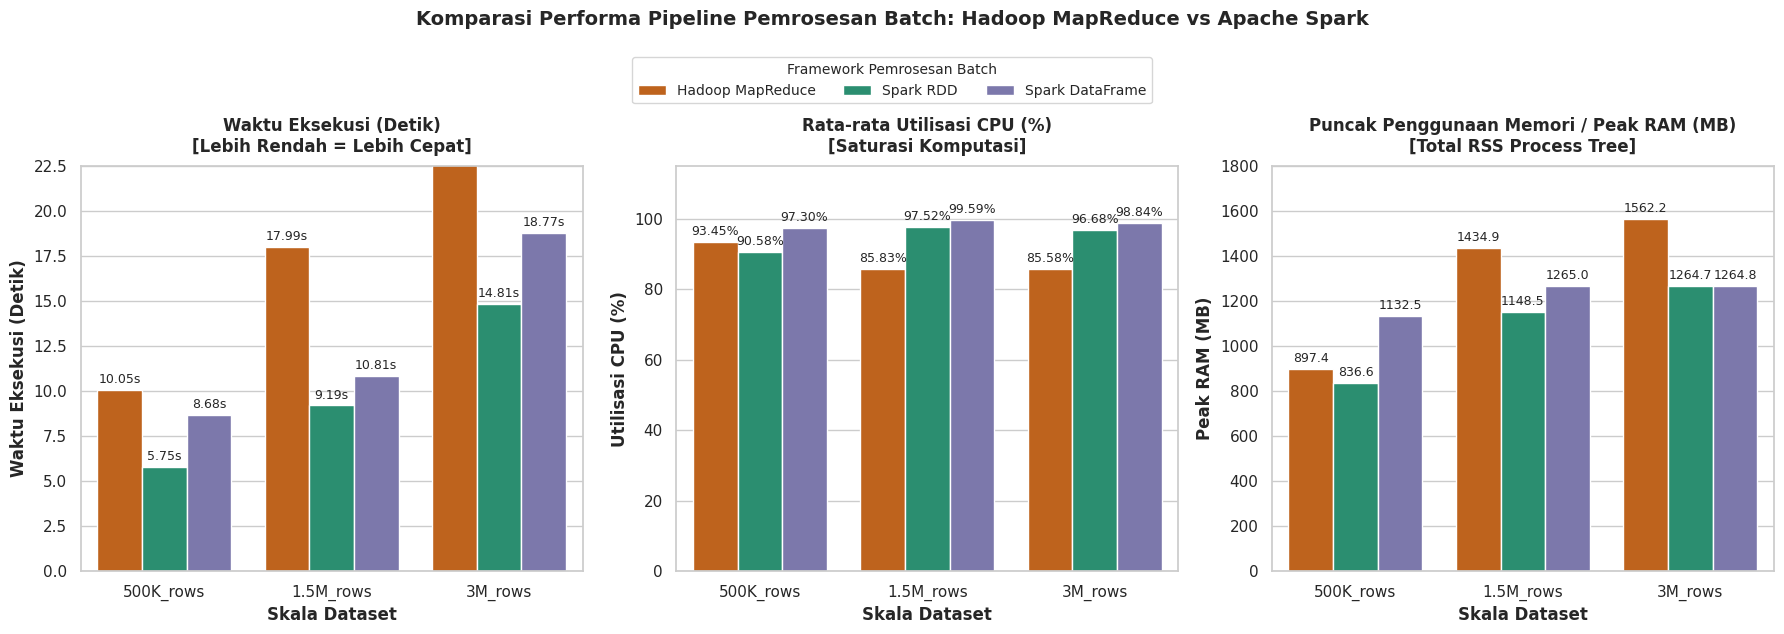

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Verifikasi Kebenaran Hasil (Output MapReduce vs Spark pada dataset 3M_rows)
print("=== Output Hadoop MapReduce (3M_rows) ===")
!cat /content/mr_3M_rows/part-00000

print("\n=== Output Spark DataFrame (3M_rows) ===")
for r in df_res:
    print(f"{r['status_code']}\t{r['total_requests']}\t{r['total_bytes']}")

# 2. Visualisasi Grafik Komparasi Performa
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.8))

palette = {
    "Hadoop MapReduce": "#d95f02",
    "Spark RDD": "#1b9e77",
    "Spark DataFrame": "#7570b3"
}

# Panel 1: Waktu Eksekusi (Detik)
sns.barplot(data=df_bench, x="Dataset", y="Waktu_Detik", hue="Framework", ax=axes[0], palette=palette)
axes[0].set_title("Waktu Eksekusi (Detik)\n[Lebih Rendah = Lebih Cepat]", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Skala Dataset", fontweight="bold")
axes[0].set_ylabel("Waktu Eksekusi (Detik)", fontweight="bold")
axes[0].set_ylim(0, 22.5)
axes[0].get_legend().remove()
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2fs", fontsize=9, padding=3)

# Panel 2: Rata-rata Utilisasi CPU (%)
sns.barplot(data=df_bench, x="Dataset", y="CPU_Persen", hue="Framework", ax=axes[1], palette=palette)
axes[1].set_title("Rata-rata Utilisasi CPU (%)\n[Saturasi Komputasi]", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Skala Dataset", fontweight="bold")
axes[1].set_ylabel("Utilisasi CPU (%)", fontweight="bold")
axes[1].set_ylim(0, 115)
axes[1].get_legend().remove()
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%", fontsize=9, padding=3)

# Panel 3: Puncak Penggunaan Memori / Peak RAM (MB)
sns.barplot(data=df_bench, x="Dataset", y="Peak_RAM_MB", hue="Framework", ax=axes[2], palette=palette)
axes[2].set_title("Puncak Penggunaan Memori / Peak RAM (MB)\n[Total RSS Process Tree]", fontsize=12, fontweight="bold", pad=10)
axes[2].set_xlabel("Skala Dataset", fontweight="bold")
axes[2].set_ylabel("Peak RAM (MB)", fontweight="bold")
axes[2].set_ylim(0, 1800)
handles, labels = axes[2].get_legend_handles_labels()
axes[2].get_legend().remove()
for container in axes[2].containers:
    axes[2].bar_label(container, fmt="%.1f", fontsize=9, padding=3)

# Legenda Terpusat di Atas & Judul Utama
fig.legend(
    handles, labels,
    title="Framework Pemrosesan Batch",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=True,
    fontsize=10,
    title_fontsize=10
)
plt.suptitle(
    "Komparasi Performa Pipeline Pemrosesan Batch: Hadoop MapReduce vs Apache Spark",
    fontsize=14,
    fontweight="bold",
    y=1.09
)
plt.tight_layout()
plt.savefig("repo_tugas2/results/grafik_komparasi_performa.png", dpi=300, bbox_inches="tight")
plt.show()